# De relatie tussen dagelijks gebruik van short-form video’s en werkgeheugenprestatie bij studenten
**Onderzoeksvraag**: Wat is het verband tussen de gemiddelde tijd per dag die studenten aan short-form video's besteden en hun werkgeheugenprestatie op een 2-back-taak?

**Hypothese**:
- Hoofdvoorspelling: Hoe meer minuten per dag een student aan short-form video's besteedt, hoe lager de accuratesse op de 2-back-taak is.
- Nevenvoorspelling: Hoe meer minuten per dag een student aan short-form video's besteedt, hoe langer de reactietijden op de 2-back-taak zijn.

## Survey
| Vraag | Antwoord | Type |
|---|---|---|
|Leeftijd | jaar | int |
|Gender | man, vrouw, anders, zeg ik liever niet | enum |
|Shortform duur per dag | min | int |
|Shortform bron |opgezocht, geschat | enum |
|Slaap duur | uur | int |

## Task
N-Back test (N = 2) afgenomen op PsyToolkit (https://www.psytoolkit.org/c/3.7.6/survey?s=m8JRm)

## Onderzoek
| Rol | Variabele | Bron |
|---|---|---|
| Onafhankelijke variabele | `shortform_min`: zelfgerapporteerde minuten per dag | survey |
| Primaire uitkomstmaat | `accuracy`: gecorrigeerde trefferkans | `experiment_data/` |
| Secundaire uitkomstmaat | `rt_median`: mediaan reactietijd op treffers in ms | `experiment_data/` |
| Covariate | `slaap`: zelfgerapporteerde aantal uur geslapen afgelopen nacht | survey |
| Sensitiviteitsanalyse | `bron_label`: opgezocht of geschat | survey |


## Imports, globals and helpers

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pingouin as pg
from dataclasses import dataclass

@dataclass(frozen=True)
class SpearmanResult:
    label: str
    n: int
    df: int
    rho: float
    p: float
    symbol: str = "r_s"

    def apa(self) -> str:
        return f"{self.symbol}({self.df}) = {fmt(self.rho)}, p {fmt_p(self.p)}"

def fmt(x: float, dec: int = 2) -> str:
    s = f"{x:.{dec}f}"
    return s.replace("0.", ".", 1) if abs(x) < 1 else s

def fmt_p(p: float) -> str:
    return "< .001" if p < .001 else f"= {fmt(p, 3)}"

ALPHA = 0.05
DATA = Path("data")

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

# style ✨
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

## Survey data

Codes (`survey.txt`):
- `consent`: 1 = ja, 2 = nee
- `gender`: 1 = man, 2 = vrouw, 3 = anders, 4 = zeg ik liever niet
- `shortform_bron`: 1 = opgezocht, 2 = geschat

In [23]:
# read data from csv
survey = pd.read_csv("./data/data.csv")

# convert and drop colums
survey["uuid"] = survey["participant"].str.split(".").str[1]
survey["consent"] = survey["consent"].map({1: "ja", 2: "nee"})
survey["gender_label"] = survey["gender"].map({1: "man", 2: "vrouw", 3: "anders", 4: "zeg ik liever niet"})
survey["bron_label"] = survey["shortform_bron"].map({1: "opgezocht", 2: "geschat"})
survey = survey[["uuid", "consent", "leeftijd", "gender_label", "shortform_min", "bron_label", "slaap"]]

display(survey)

,uuid,consent,leeftijd,gender_label,shortform_min,bron_label,slaap
0,06ac6dd9-2581-4147-a11b-08da3cbed35e,ja,21.0,vrouw,88.0,opgezocht,6.0
1,10ecf204-6e66-479d-9418-7c05b860ee7e,ja,23.0,vrouw,20.0,opgezocht,9.0
2,252c0ccc-6b8b-48b5-968b-4fa9832ee01f,ja,21.0,man,180.0,opgezocht,6.0
3,2614051e-694e-4476-80c7-c5a2d1c9e8e5,ja,20.0,anders,60.0,opgezocht,8.0
4,3798b14a-1955-49fb-a3b7-26004923a6ac,ja,20.0,vrouw,40.0,opgezocht,10.0
5,3e84d5fd-2dcf-40f0-bb08-43427945129d,ja,19.0,vrouw,360.0,opgezocht,7.0
6,63359fbc-512e-4b0c-b45a-fbcc668dd068,ja,20.0,man,120.0,geschat,6.0
7,73b3b8e0-d90c-40b1-95ae-7500b6d1896f,ja,20.0,vrouw,240.0,opgezocht,7.0
8,75799c25-1be6-4e28-ab18-b2b888f8b6f9,ja,23.0,man,90.0,geschat,6.0
9,8d86fb91-4287-41d8-82f3-ecd43f2e4b7d,nee,NaN,NaN,NaN,NaN,NaN


## Task data
Voor elk participant die de task heeft afgerond is er een data bestand met de resultaten in `data/experiment_data/`.

Elk bestand bestaad uit rijen, een rij stelt een trail voor.
Er waren 3 tests (blok) van 25 trails, geeft: 3 x 25 = 75 rijen per bestand.

Uit de door PsyToolkit geleverde r script `data/analize_nback2.r`, hebben we de volgende kolommen afgeleidt:

| kolom | naam | betekenis |
|---|---|---|
| 1 | `block` | 1 = practice, 2–3 = test |
| 2 | `trial` | trial nummer in de blok |
| 3 | `target` | 1 = de letter is hetzelfde als twee ervoor |
| 4 | `correct` | 1 = correct response |
| 5–7 | `hit`, `miss`, `false_alarm` | uitkomst |
| 8 | `rt` | reactietijd in ms; 3000 = geen invoer |
| 9–12 | | niet relevant |

In [24]:
trial_cols = ["block", "trial", "target", "correct", "hit", "miss", "false_alarm", "rt", "9", "10", "11", "12"]

# load by iterating over the files in experiment_data
frames = []
for file in (DATA / "experiment_data").glob("nback2.*.txt"):
    df = pd.read_csv(file, sep=r"\s+", header=None, names=trial_cols)
    df["uuid"] = file.name.split(".")[3]
    frames.append(df)

trials = pd.concat(frames, ignore_index=True)
trials = trials[["uuid", "block", "trial", "target", "correct", "hit", "miss", "false_alarm", "rt"]]

# remove incomplete entries (survey only contains completed entries)
trials = trials[trials["uuid"].isin(survey.uuid.unique())]

# remove practice trials (block 1)
trials = trials[trials["block"] > 1]

print(f"{len(trials.uuid.unique())} participanten, {len(trials)} trials")

display(trials)


18 participanten, 900 trials


,uuid,block,trial,target,correct,hit,miss,false_alarm,rt
25,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,1,0,1,0,0,0,3000
26,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,2,0,1,0,0,0,3000
27,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,3,0,1,0,0,0,3000
28,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,4,0,1,0,0,0,3000
29,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,5,1,1,1,0,0,972
...,...,...,...,...,...,...,...,...,...
1345,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,21,0,1,0,0,0,3000
1346,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,22,0,1,0,0,0,3000
1347,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,23,0,1,0,0,0,3000
1348,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,24,0,1,0,0,0,3000


## Task measures
De volgende task measures worden berekend over de test blocks:
- Hit rate = hit / targets
- False alarm rate = false alarms / non-targets
- Accuracy = verhouding van alle trials dat correct is
- Reaction time median
- Reaction time mean

In [25]:
def task_measures(tr: pd.DataFrame) -> pd.DataFrame:
    def one(d):
        target = d[d.target == 1]
        non_target = d[d.target == 0]

        hits = target.correct.sum()
        fas = (non_target.false_alarm).sum()

        hit_rt = target.loc[target.correct == 1, "rt"]

        hit_rate = hits / len(target)
        fa_rate = fas / len(non_target)

        accuracy = (hit_rate - fa_rate) * 100

        return pd.Series({
            "n_trials": len(d),
            "n_targets": len(target),
            "hits": hits,
            "false_alarms": fas,
            "hit_rate": hit_rate,
            "fa_rate": fa_rate,
            "accuracy": accuracy,
            "rt_median": hit_rt.median(),
            "rt_mean": hit_rt.mean(),
            "n_rt": len(hit_rt),
        })
    return tr.groupby("uuid")[tr.columns.drop("uuid")].apply(one)

dataset = survey.merge(task_measures(trials), left_on="uuid", right_index=True, how="left")
display(dataset)

,uuid,consent,leeftijd,gender_label,shortform_min,bron_label,slaap,n_trials,n_targets,hits,false_alarms,hit_rate,fa_rate,accuracy,rt_median,rt_mean,n_rt
0,06ac6dd9-2581-4147-a11b-08da3cbed35e,ja,21.0,vrouw,88.0,opgezocht,6.0,50.0,20.0,20.0,1.0,1.000,0.033,96.667,400.5,451.200,20.0
1,10ecf204-6e66-479d-9418-7c05b860ee7e,ja,23.0,vrouw,20.0,opgezocht,9.0,50.0,20.0,15.0,0.0,0.750,0.000,75.000,563.0,560.133,15.0
2,252c0ccc-6b8b-48b5-968b-4fa9832ee01f,ja,21.0,man,180.0,opgezocht,6.0,50.0,16.0,10.0,1.0,0.625,0.029,59.559,642.5,661.900,10.0
3,2614051e-694e-4476-80c7-c5a2d1c9e8e5,ja,20.0,anders,60.0,opgezocht,8.0,50.0,15.0,11.0,0.0,0.733,0.000,73.333,641.0,641.000,11.0
4,3798b14a-1955-49fb-a3b7-26004923a6ac,ja,20.0,vrouw,40.0,opgezocht,10.0,50.0,12.0,11.0,1.0,0.917,0.026,89.035,422.0,443.000,11.0
5,3e84d5fd-2dcf-40f0-bb08-43427945129d,ja,19.0,vrouw,360.0,opgezocht,7.0,50.0,14.0,7.0,2.0,0.500,0.056,44.444,453.0,608.429,7.0
6,63359fbc-512e-4b0c-b45a-fbcc668dd068,ja,20.0,man,120.0,geschat,6.0,50.0,20.0,20.0,4.0,1.000,0.133,86.667,429.0,517.750,20.0
7,73b3b8e0-d90c-40b1-95ae-7500b6d1896f,ja,20.0,vrouw,240.0,opgezocht,7.0,50.0,14.0,10.0,2.0,0.714,0.056,65.873,701.0,710.000,10.0
8,75799c25-1be6-4e28-ab18-b2b888f8b6f9,ja,23.0,man,90.0,geschat,6.0,50.0,10.0,7.0,3.0,0.700,0.075,62.500,616.0,617.429,7.0
9,8d86fb91-4287-41d8-82f3-ecd43f2e4b7d,nee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Exclusion criteria
Deelnemers worden uitgesloten met:
- geen consent
- ontbrekende gegevens
- gecorrigeerde trefferkans van nul of lager


In [26]:
num_full = len(dataset)
excluded = {}

def exclude(df: pd.DataFrame, keep: pd.Series, reden: str) -> pd.DataFrame:
    excluded[reden] = int((~keep).sum())
    return df[keep]

dataset = exclude(dataset, dataset["consent"] == "ja", "het ontbreken van toestemming")
dataset = exclude(dataset, dataset["accuracy"] > 0, "een gecorrigeerde trefferkans van nul of lager")
dataset = exclude(dataset, dataset.notna().all(axis=1), "ontbrekende gegevens")

dataset = dataset.reset_index(drop=True)

print(f"Totaal participanten: {num_full}\nParticipanten excl. criteria: {len(dataset)}")
print("Uitgesloten:", excluded)
dataset

Totaal participanten: 19
Participanten excl. criteria: 17
Uitgesloten: {'het ontbreken van toestemming': 1, 'een gecorrigeerde trefferkans van nul of lager': 1, 'ontbrekende gegevens': 0}


,uuid,consent,leeftijd,gender_label,shortform_min,bron_label,slaap,n_trials,n_targets,hits,false_alarms,hit_rate,fa_rate,accuracy,rt_median,rt_mean,n_rt
0,06ac6dd9-2581-4147-a11b-08da3cbed35e,ja,21.0,vrouw,88.0,opgezocht,6.0,50.0,20.0,20.0,1.0,1.000,0.033,96.667,400.5,451.200,20.0
1,10ecf204-6e66-479d-9418-7c05b860ee7e,ja,23.0,vrouw,20.0,opgezocht,9.0,50.0,20.0,15.0,0.0,0.750,0.000,75.000,563.0,560.133,15.0
2,252c0ccc-6b8b-48b5-968b-4fa9832ee01f,ja,21.0,man,180.0,opgezocht,6.0,50.0,16.0,10.0,1.0,0.625,0.029,59.559,642.5,661.900,10.0
3,2614051e-694e-4476-80c7-c5a2d1c9e8e5,ja,20.0,anders,60.0,opgezocht,8.0,50.0,15.0,11.0,0.0,0.733,0.000,73.333,641.0,641.000,11.0
4,3798b14a-1955-49fb-a3b7-26004923a6ac,ja,20.0,vrouw,40.0,opgezocht,10.0,50.0,12.0,11.0,1.0,0.917,0.026,89.035,422.0,443.000,11.0
5,3e84d5fd-2dcf-40f0-bb08-43427945129d,ja,19.0,vrouw,360.0,opgezocht,7.0,50.0,14.0,7.0,2.0,0.500,0.056,44.444,453.0,608.429,7.0
6,63359fbc-512e-4b0c-b45a-fbcc668dd068,ja,20.0,man,120.0,geschat,6.0,50.0,20.0,20.0,4.0,1.000,0.133,86.667,429.0,517.750,20.0
7,73b3b8e0-d90c-40b1-95ae-7500b6d1896f,ja,20.0,vrouw,240.0,opgezocht,7.0,50.0,14.0,10.0,2.0,0.714,0.056,65.873,701.0,710.000,10.0
8,75799c25-1be6-4e28-ab18-b2b888f8b6f9,ja,23.0,man,90.0,geschat,6.0,50.0,10.0,7.0,3.0,0.700,0.075,62.500,616.0,617.429,7.0
9,8f8d17b9-d72d-4f76-b254-a842afa2a753,ja,19.0,vrouw,150.0,opgezocht,7.0,50.0,14.0,9.0,4.0,0.643,0.111,53.175,594.0,621.556,9.0


## Descriptive statistics

In [27]:
N = len(dataset)
age_stat = dataset.leeftijd.describe().to_dict()
gender_stat = dataset.gender_label.value_counts().to_dict()

print(f"N = {N}")
print(f"Leeftijd: M = {age_stat['mean']:.1f}, SD = {age_stat['std']:.1f}, range {int(age_stat['min'])}-{int(age_stat['max'])}")
print("Gender:", gender_stat)
print("Short-form bron:", dataset.bron_label.value_counts().to_dict())

desc_vars = ["shortform_min", "slaap", "accuracy", "hit_rate", "fa_rate", "rt_median"]
desc = dataset[desc_vars].agg(["count", "mean", "std", "median", "min", "max", "skew"]).T
display(desc)

N = 17
Leeftijd: M = 20.4, SD = 1.6, range 17-23
Gender: {'vrouw': 8, 'man': 7, 'anders': 1, 'zeg ik liever niet': 1}
Short-form bron: {'opgezocht': 11, 'geschat': 6}


,count,mean,std,median,min,max,skew
shortform_min,17.0,130.176,99.903,120.000,0.000,360.000,0.952
slaap,17.0,7.118,1.269,7.000,5.000,10.000,0.585
accuracy,17.0,67.730,21.207,73.333,20.000,96.667,-0.734
hit_rate,17.0,0.749,0.167,0.733,0.474,1.000,-0.151
fa_rate,17.0,0.072,0.076,0.056,0.000,0.300,1.765
rt_median,17.0,547.000,116.363,563.000,370.000,718.000,-0.141


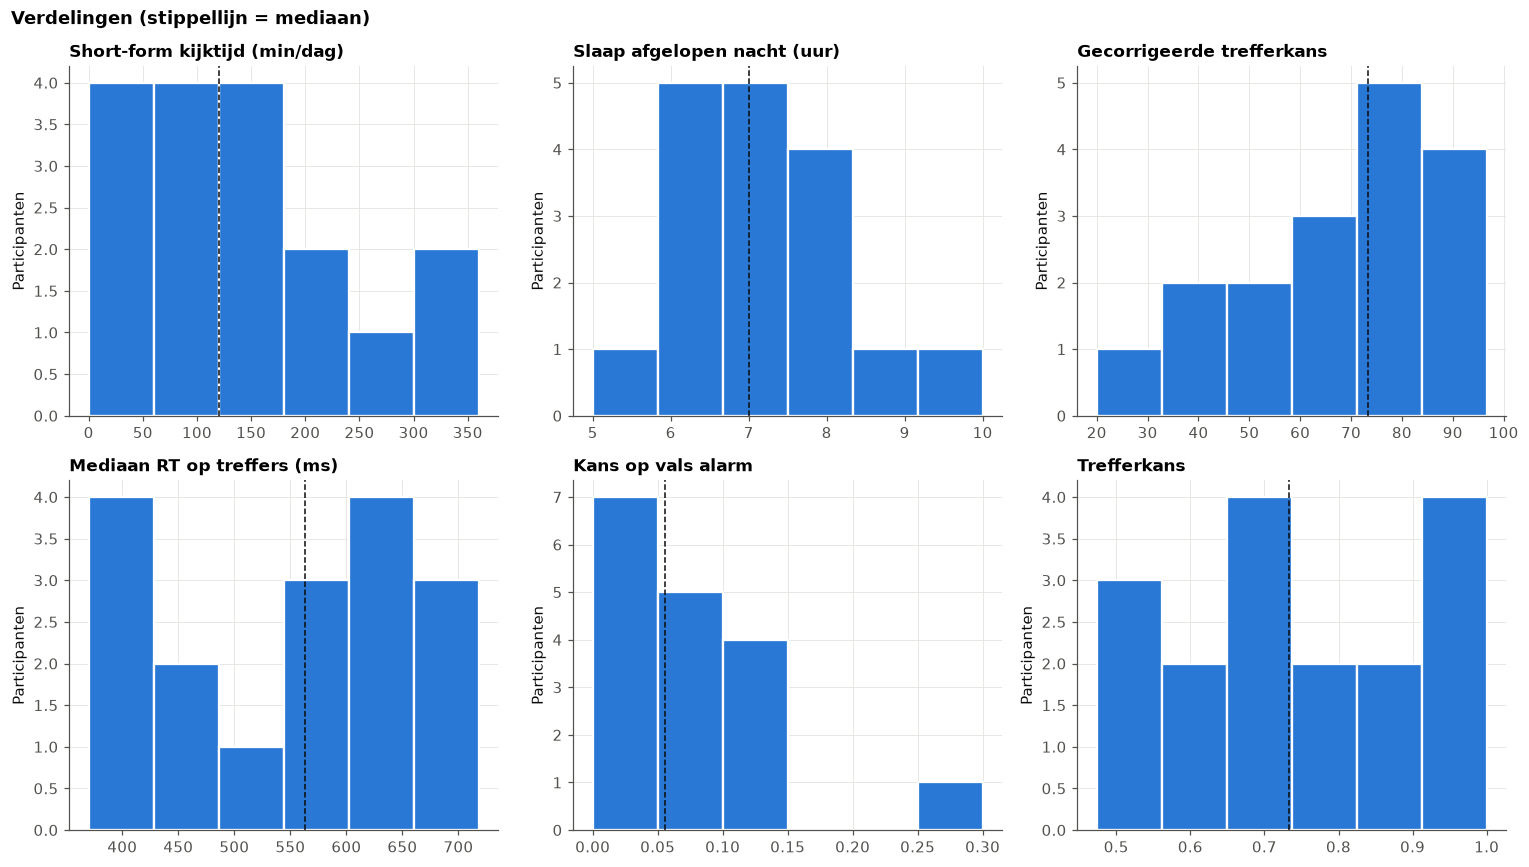

In [28]:
labels = {
    "shortform_min": "Short-form kijktijd (min/dag)",
    "slaap": "Slaap afgelopen nacht (uur)",
    "accuracy": "Gecorrigeerde trefferkans",
    "rt_median": "Mediaan RT op treffers (ms)",
    "fa_rate": "Kans op vals alarm",
    "hit_rate": "Trefferkans"
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (v, lab) in zip(axes.flat, labels.items()):
    x = dataset[v].dropna()
    ax.hist(x, bins="auto", color=BLUE, edgecolor="white", linewidth=1.5)
    ax.axvline(x.median(), color=INK, linewidth=1, linestyle="--")
    ax.set_title(lab, loc="left")
    ax.set_ylabel("Participanten")
fig.suptitle("Verdelingen (stippellijn = mediaan)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## Analysis


In [29]:
def spearman(data: pd.DataFrame, x: str, y: str, covar: str | None = None, label: str = "") -> SpearmanResult:
    d = data[[x, y] + ([covar] if covar else [])].dropna()
    n = len(d)

    if covar:
        pc = pg.partial_corr(data=d, x=x, y=y, covar=covar, method="spearman")
        rho, p, df = pc["r"].iloc[0], pc["p_val"].iloc[0], n - 3
    else:
        rho, p = stats.spearmanr(d[x], d[y])
        df = n - 2

    return SpearmanResult(label, n, df, rho, p, symbol="r" if covar else "r_s")

opgezocht = dataset[dataset.bron_label == "opgezocht"]

results = [
    spearman(dataset,   "shortform_min", "accuracy",  label="Hoofd: kijktijd x gecorrigeerde trefferkans"),
    spearman(dataset,   "shortform_min", "rt_median", label="Neven: kijktijd x RT"),
    spearman(dataset,   "shortform_min", "accuracy",  covar="slaap", label="Covariaat: controle slaap"),
    spearman(opgezocht, "shortform_min", "accuracy",  label="Sensitiviteit: alleen opgezocht"),
]

for result in results:
    print(f"{result.label} (n = {result.n}):\n\t{result.apa()}\n")

Hoofd: kijktijd x gecorrigeerde trefferkans (n = 17):
	r_s(15) = -.37, p = .145

Neven: kijktijd x RT (n = 17):
	r_s(15) = .58, p = .015

Covariaat: controle slaap (n = 17):
	r_s(14) = -.44, p = .092

Sensitiviteit: alleen opgezocht (n = 11):
	r_s(9) = -.30, p = .370



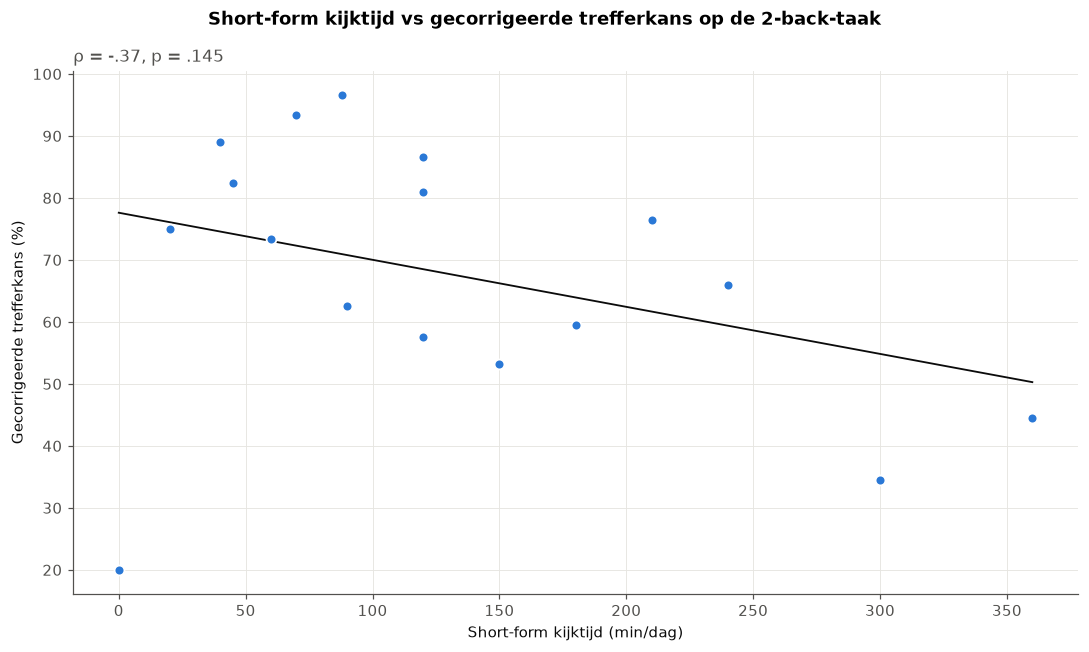

In [38]:
def scatter(ax, x, y, res: SpearmanResult, xlab, ylab):
    ax.scatter(x, y, s=42, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3)
    b, a = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, a + b * xs, color=INK, linewidth=1.2, zorder=2)
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.set_title(f"ρ = {fmt(res.rho)}, p {fmt_p(res.p)}", loc="left", fontweight="normal", color=MUTED)

fig, ax = plt.subplots(figsize=(10, 6))
scatter(ax, dataset.shortform_min, dataset.accuracy, results[0], "Short-form kijktijd (min/dag)", "Gecorrigeerde trefferkans (%)")
fig.suptitle("Short-form kijktijd vs gecorrigeerde trefferkans op de 2-back-taak", fontweight="bold")
fig.tight_layout()


---


## Appendix: variables.tex
Download here: [variables.tex](docs/assets/variables.tex)

In [31]:
# format:
# \newcommand{\variable}{value}

def num(x: float, dec: int) -> str:
    return f"{x:.{dec}f}"

reasons = {r: k for r, k in excluded.items() if k > 0}
if len(reasons) > 1:
    parts = [f"{r} ($n = {k}$)" for r, k in reasons.items()]
    reden = ", ".join(parts[:-1]) + " en " + parts[-1]
else:
    reden = next(iter(reasons), "")

n_opgezocht = int((dataset.bron_label == "opgezocht").sum())

variables = {
    "Ntotaal": num_full,
    "Nvrouw": int(gender_stat.get("vrouw", 0)),
    "Nman": int(gender_stat.get("man", 0)),
    "Nandere": int(gender_stat.get("anders", 0) + gender_stat.get("zeg ik liever niet", 0)),
    "Mage": num(age_stat["mean"], 1),
    "SDage": num(age_stat["std"], 1),
    "MMage": f"{int(age_stat['min'])}-{int(age_stat['max'])}",
    "Nuitgesloten": num_full - N,
    "Uitsluitreden": reden,
    "Nanalyse": N,
    "Nopgezocht": n_opgezocht,
    "Popgezocht": num(100 * n_opgezocht / N, 0),
}

# tabel 1 (kolom, prefix, decimalen m/sd, decimalen min/max)
table = [
    ("shortform_min", "Kijktijd", 1, 0),
    ("accuracy",      "Acc",      1, 1),
    ("rt_median",     "Rt",       0, 0),
    ("slaap",         "Slaap",    1, 0),
]
for col, prefix, dec, dec_range in table:
    x = dataset[col]
    variables |= {
        f"{prefix}M":   num(x.mean(), dec),
        f"{prefix}SD":  num(x.std(), dec),
        f"{prefix}Min": num(x.min(), dec_range),
        f"{prefix}Max": num(x.max(), dec_range),
    }

# Correlaties in dezelfde volgorde als results
for prefix, r in zip(["Hoofd", "Neven", "Partieel", "Sens"], results):
    variables |= {
        f"{prefix}N":   r.n,
        f"{prefix}Df":  r.df,
        f"{prefix}Rho": fmt(r.rho),
        f"{prefix}P":   fmt_p(r.p),
    }

tex = "\n".join(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in variables.items()) + "\n"
Path("docs/assets/variables.tex").write_text(tex, encoding="utf-8")
print(tex)

\newcommand{\Ntotaal}{19}
\newcommand{\Nvrouw}{8}
\newcommand{\Nman}{7}
\newcommand{\Nandere}{2}
\newcommand{\Mage}{20.4}
\newcommand{\SDage}{1.6}
\newcommand{\MMage}{17-23}
\newcommand{\Nuitgesloten}{2}
\newcommand{\Uitsluitreden}{het ontbreken van toestemming ($n = 1$) en een gecorrigeerde trefferkans van nul of lager ($n = 1$)}
\newcommand{\Nanalyse}{17}
\newcommand{\Nopgezocht}{11}
\newcommand{\Popgezocht}{65}
\newcommand{\KijktijdM}{130.2}
\newcommand{\KijktijdSD}{99.9}
\newcommand{\KijktijdMin}{0}
\newcommand{\KijktijdMax}{360}
\newcommand{\AccM}{67.7}
\newcommand{\AccSD}{21.2}
\newcommand{\AccMin}{20.0}
\newcommand{\AccMax}{96.7}
\newcommand{\RtM}{547}
\newcommand{\RtSD}{116}
\newcommand{\RtMin}{370}
\newcommand{\RtMax}{718}
\newcommand{\SlaapM}{7.1}
\newcommand{\SlaapSD}{1.3}
\newcommand{\SlaapMin}{5}
\newcommand{\SlaapMax}{10}
\newcommand{\HoofdN}{17}
\newcommand{\HoofdDf}{15}
\newcommand{\HoofdRho}{-.37}
\newcommand{\HoofdP}{= .145}
\newcommand{\NevenN}{17}
\newcommand{\Neven